# Descomposición de series temporales

El objetivo de este ejercicio es decomponer dos series temporales. Primero, habrá que determinar si la descomposición será aditiva o multiplicativa en función de la variación de la amplitud de la serie. 

1. **Importar librerías**

    Importamos las librerías necesarias para le ejecución del problema.
- read_csv de pandas para la lectura de datos
- pyplot para la visualización de los datos
- seasonal_decompose de statsmodels.tsa.seasonal para la descomposición de la serie

2. **Lectura de datos con pandas**

    Hay disponibles dos conjuntos de datos para analizar. Para cada uno de los *datasets*:
- Comprobar frecuencia de muestreo. ¿Es una serie temporal de alta frecuencia?
- Visualizar serie temporal

3. **Descomposición de las series**

    Para la descomposición de las series se deberá consultar la [librería seasonal_decompose](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html) para ver qué parametros de entrada requiere cada tipo de decomposición.
- Determinar tipo de descomposición
- Decomposición y visualización de componentes


In [1]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
serie_1 = pd.read_csv('serie_temporal1.csv')
serie_1.head()

,Date,Value
0,2020-01-01,152.000000
1,2020-01-02,150.905913
2,2020-01-03,81.804686
3,2020-01-04,182.689188
4,2020-01-05,156.552301


In [3]:
serie_2 = pd.read_csv('serie_temporal2.csv')
serie_2.head()

,DATE,Value
0,01-01-1985,72.5052
1,02-01-1985,70.6720
2,03-01-1985,62.4502
3,04-01-1985,57.4714
4,05-01-1985,55.3151


## **SERIE1**

In [4]:
serie_1['Date'] = pd.to_datetime(serie_1['Date'])
print(serie_1['Date'].diff().dropna().value_counts())

Date
1 days    1460
Name: count, dtype: int64


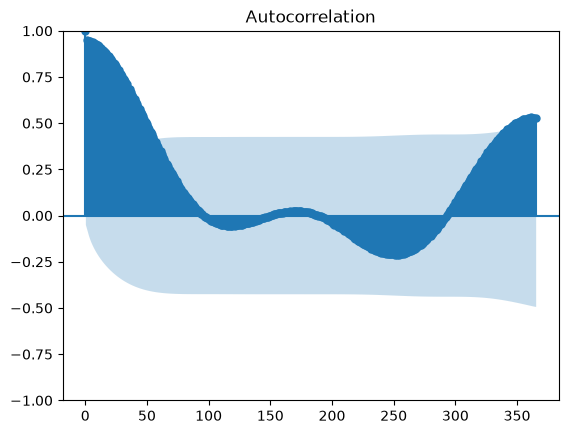

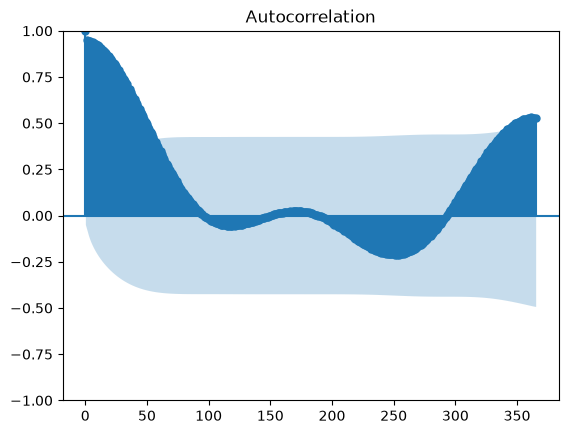

In [ ]:
plot_acf(serie_1['Value'], lags=365)

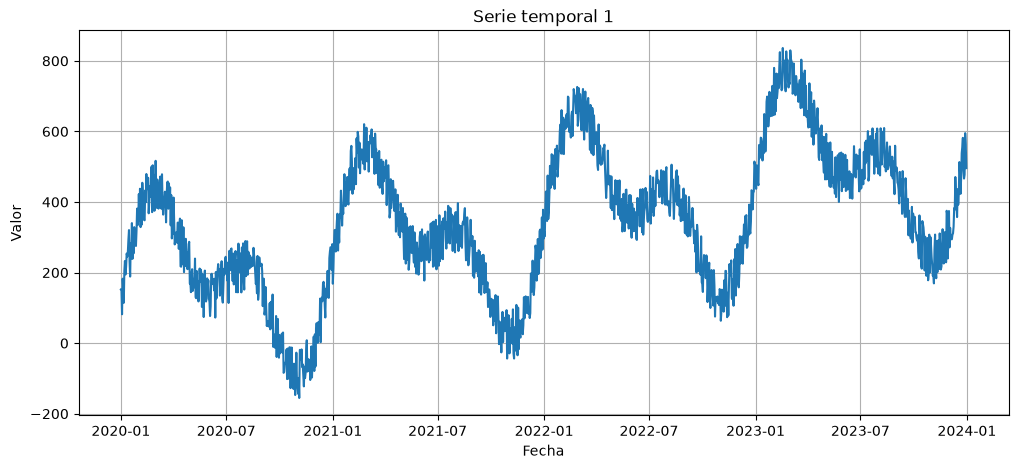

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(serie_1['Date'], serie_1['Value'])
plt.title('Serie temporal 1')
plt.xlabel('Fecha')
plt.ylabel('Valor')
plt.grid()
plt.show()

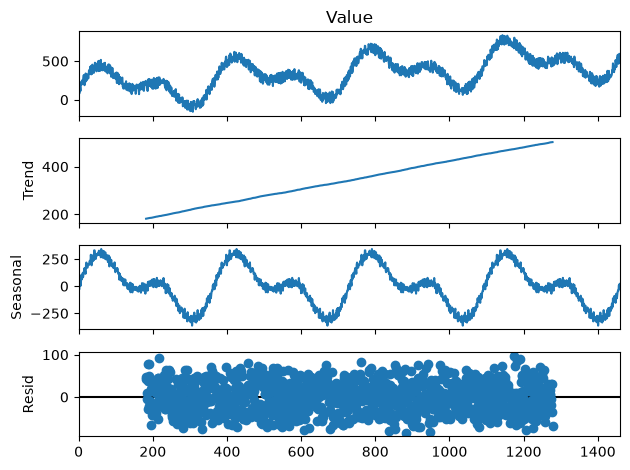

In [7]:
descomposicion_1 = seasonal_decompose(
    serie_1['Value'],
    model='additive',
    period=365
)

descomposicion_1.plot()
plt.show()

## **SERIE2**

In [8]:
serie_2['DATE'] = pd.to_datetime(serie_2['DATE'])
print(serie_2['DATE'].diff().value_counts())

DATE
31 days    231
30 days    132
28 days     25
29 days      8
Name: count, dtype: int64


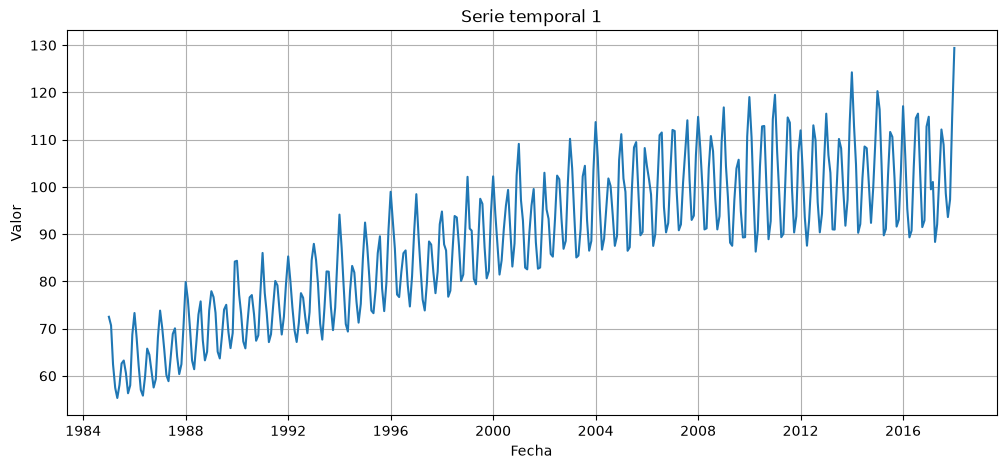

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(serie_2['DATE'], serie_2['Value'])
plt.title('Serie temporal 1')
plt.xlabel('Fecha')
plt.ylabel('Valor')
plt.grid()
plt.show()

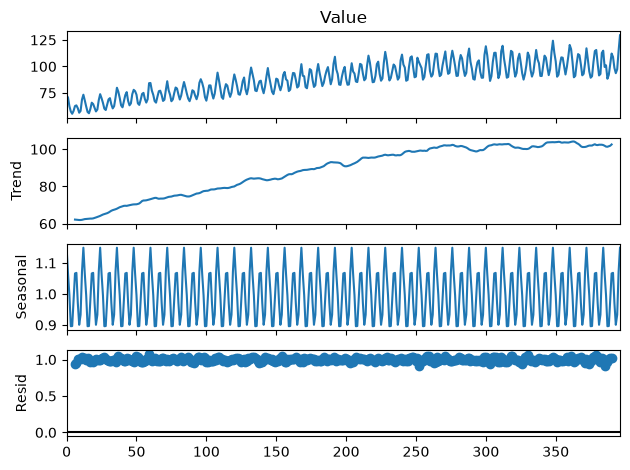

In [13]:
descomposicion_2 = seasonal_decompose(
    serie_2['Value'],
    model='multiplicative',
    period=12
)

descomposicion_2.plot()
plt.show()